In [1]:
%matplotlib inline

import sys
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import constants
# import root_pandas
from geometry.belle2_cdc import BELLE2
from geometry.bes3_mdc import BES3
from geometry.stcf_mdc import STCF
from track_propagation_in_DC import *

from IPython.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))

# Create CDC model

### default values

In [2]:
#dc = DC(BELLE2)
#dc = DC(BES3)
#dc = DC(STCF)  #for actual geometries of belle-II, BESIII, STCF

### user specific values

In [23]:
dc_dummy = {
    "A": np.array([-100.0, 120.0]),
    "B": np.array([ 100.0, 120.0]),
    "C": np.array([ -80.0,  80.0]),
    "D": np.array([  80.0,  80.0]),
    "E": np.array([ -60.0,  40.0]),
    "F": np.array([  60.0,  40.0]),
    "G": np.array([-999.0,  20.0]),
    "H": np.array([-999.0,  20.0]),
    "rhosize_min": np.array([1.0, 1.0, 1.5, 2.0, 2.5]),
    "rhosize_max": np.array([1.0, 2.0, 2.5, 3.0, 4.0]),
    "rho_min": np.array([20., 35., 50., 70., 95.]),
    "rho_max": np.array([30., 45., 65., 90.,115.]),
    "nLayers": np.array([1, 3, 6, 6, 6]),
    "nCells": np.array([8, 12, 16, 20, 24]),
    "rhosize_threshold": 1.2,
    "Bz": 1.0,
}

dc = DC(dc_dummy)

# Input parameters of each track

In [24]:
d_trk1 = {
            'q':  1,            # charge (+1 or -1)
            'px': 1.10,         # x-component of the 3-momentum 
            'py': 0.89,         # y-component of the 3-momentum
            'pz': -0.29,        # z-component of the 3-momentum
            'prodVtxX': 4.39,   # x-component of the production vertex
            'prodVtxY': 3.21,   # y-component of the production vertex
            'prodVtxZ': -1.27,  # z-component of the production vertex
        }

d_trk2 = {
            'q':  -1,
            'px': 0.17,
            'py': 0.03,
            'pz': -0.07,
            'prodVtxX': 4.39,
            'prodVtxY': 3.21, 
            'prodVtxZ': -1.27, 
        }

d_trk3 = {
            'q':  -1,
            'px': 0.17,
            'py': 0.03,
            'pz': 0.5,
            'prodVtxX': 4.39,
            'prodVtxY': 50.1, 
            'prodVtxZ': 49.7, 
        }

# Compute trajectories and evaluate the number of CDC hits

In [25]:
step=0.1  # by default, the steps are in arc-length in the (x-y) plane

trk1 = Trajectory(d_trk1, dc, step)  
trk2 = Trajectory(d_trk2, dc, step) 
trk3 = Trajectory(d_trk3, dc, step) 

print(f'step = {step}')
print(f'track1: {trk1.DChits} DC hits')
print(f'track2: {trk2.DChits} DC hits')
print(f'track3: {trk3.DChits} DC hits')

    
    

step = 0.1
track1: 22 DC hits
track2: 27 DC hits
track3: 2 DC hits


In [26]:
trk1.points.head()

,phi,s,x,y,z,layer_id,cell_id,rho_size,rho_size_class,cumSum,nStepsIncell
0,0.680157,5.471797,4.423892,3.237418,-1.278935,-1,-1,-1.0,-1,1,146
1,0.679921,5.571797,4.501646,3.300301,-1.299430,-1,-1,-1.0,-1,1,146
2,0.679685,5.671797,4.579416,3.363165,-1.319925,-1,-1,-1.0,-1,1,146
3,0.679450,5.771797,4.657200,3.426010,-1.340421,-1,-1,-1.0,-1,1,146
4,0.679214,5.871797,4.735000,3.488838,-1.360916,-1,-1,-1.0,-1,1,146


In [27]:
print(trk1.points)

           phi           s          x          y          z  layer_id  \
0     0.680157    5.471797   4.423892   3.237418  -1.278935        -1   
1     0.679921    5.571797   4.501646   3.300301  -1.299430        -1   
2     0.679685    5.671797   4.579416   3.363165  -1.319925        -1   
3     0.679450    5.771797   4.657200   3.426010  -1.340421        -1   
4     0.679214    5.871797   4.735000   3.488838  -1.360916        -1   
...        ...         ...        ...        ...        ...       ...   
1089  0.423434  114.371797  96.907002  60.168024 -23.598359        21   
1090  0.423198  114.471797  96.998176  60.209102 -23.618855        21   
1091  0.422963  114.571797  97.089359  60.250159 -23.639350        21   
1092  0.422727  114.671797  97.180551  60.291195 -23.659845        21   
1093  0.422491  114.771797  97.271753  60.332209 -23.680341        21   

      cell_id  rho_size rho_size_class  cumSum  nStepsIncell  
0          -1      -1.0             -1       1           146

In [28]:
print(trk1.SL_hits())

[1, 3, 6, 6, 6]


# Make 2-d plots

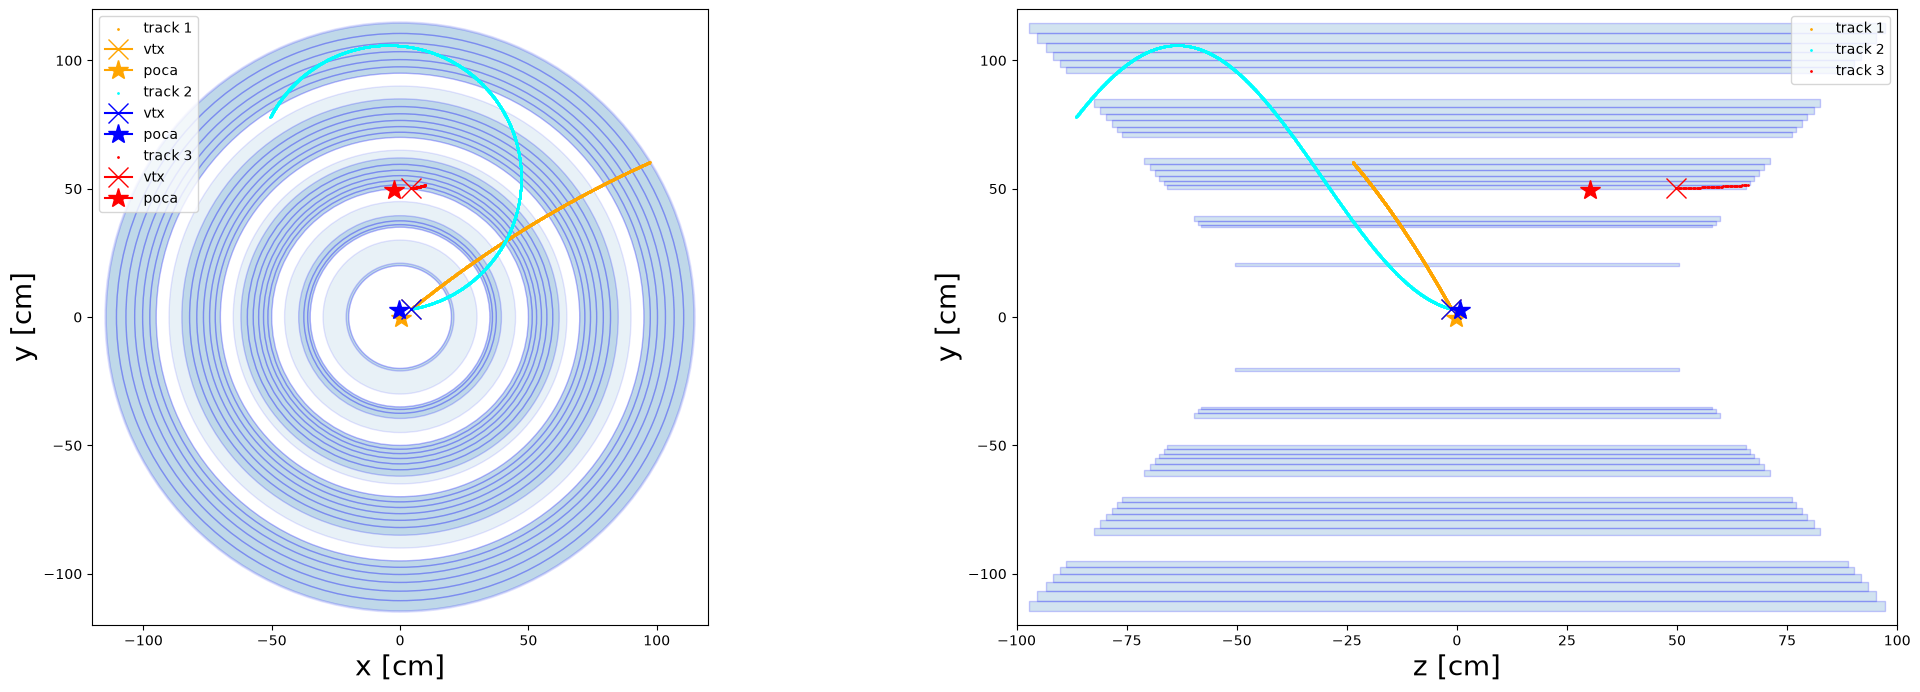

In [29]:
fig, axs = plt.subplots(1, 2, figsize = (25,8))


## (x-y) plane
ax = axs[0]
dc.xy_contour(fig, ax)
# dc.xy_cells(fig, ax) # if your model contains a lot of cells you may want to comment this line (it is slow)
trk1.xy_trajectory(ax, 'track 1', 'orange')
trk1.xy_vertex(ax, 'vtx', 'orange')
trk1.xy_poca(ax, 'poca', 'orange')

trk2.xy_trajectory(ax, 'track 2', 'cyan')
trk2.xy_vertex(ax, 'vtx', 'b')
trk2.xy_poca(ax, 'poca', 'b')

trk3.xy_trajectory(ax, 'track 3', 'red')
trk3.xy_vertex(ax, 'vtx', 'r')
trk3.xy_poca(ax, 'poca', 'r')
ax.legend()

## (z-y) plane
ax = axs[1]
# dc.zy_contour(fig, ax)
dc.zy_layers(fig, ax) 
trk1.zy_trajectory(ax, 'track 1', 'orange')
trk1.zy_vertex(ax, '', 'orange')
trk1.zy_poca(ax, '', 'orange')

trk2.zy_trajectory(ax, 'track 2', 'cyan')
trk2.zy_vertex(ax, '', 'b')
trk2.zy_poca(ax, '', 'b')

trk3.zy_trajectory(ax, 'track 3', 'red')
trk3.zy_vertex(ax, '', 'r')
trk3.zy_poca(ax, '', 'r')
ax.legend()
plt.show();

fig.savefig('TrEst2D.pdf')

# Make a 3-d plot

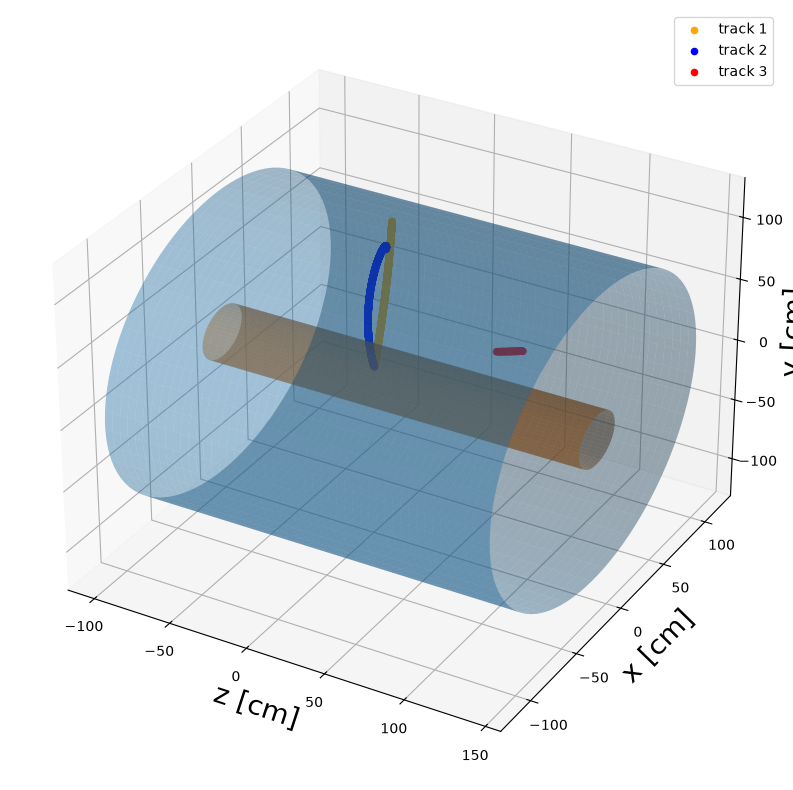

In [18]:
# %matplotlib notebook

def cylinder(r, h, a=0, nt=100, nv =50):
        """
        parametrize the cylinder of radius r, height h, base point a
        """
        theta = np.linspace(0, 2*np.pi, nt)
        v = np.linspace(a, a+h, nv )
        theta, v = np.meshgrid(theta, v)
        x = r*np.cos(theta)
        y = r*np.sin(theta)
        z = v
        return x, y, z

fig = plt.figure(figsize = (12,10))
ax = plt.axes(projection='3d')

x_outer, y_outer, z_outer = cylinder(r=dc.rho_max[-1],h=2416.9*0.1, a=dc.A[0])
x_inner, y_inner, z_inner = cylinder(r=dc.rho_min[0], h=2416.9*0.1, a=dc.A[0]) 
ax.plot_surface(z_outer, x_outer, y_outer, alpha = 0.4)   
ax.plot_surface(z_inner, x_inner, y_inner, alpha = 0.5)   

ax.scatter3D(trk1.points.z, trk1.points.y, trk1.points.x, c='orange', label='track 1')
ax.scatter3D(trk2.points.z, trk2.points.y, trk2.points.x, c='blue',   label='track 2')
ax.scatter3D(trk3.points.z, trk3.points.y, trk3.points.x, c='red',   label='track 3')


ax.set_xlabel('z [cm]', fontsize=20)
ax.set_ylabel('x [cm]', fontsize=20)
ax.set_zlabel('y [cm]', fontsize=20)
plt.legend()

# plt.tight_layout()
plt.show()
fig.savefig('TrEst3D.pdf')